# 01 探索分析

資料規模、評分分布、時間範圍、新食譜（cold）比例，以及食譜內容和 5 分比例的關係。對應報告第 1 部分。
本 notebook 不選任何超參數。

In [1]:
%load_ext autoreload
%autoreload 2

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import *
from features import (RecipeSets, build_features, group_columns, load_interactions, load_recipes,
                      make_snapshot, user_prior, weighted_average, year_snapshot)
from models import (VARIANTS, baseline_constant, fit_lr, lr_coefficients, predict, training_set,
                    tune_beta, tune_weighted_average)
from evaluation import auc, compare, evaluate, mean_ci, pretty
from ranking import ranking_metrics, sample_candidates

warnings.filterwarnings("ignore", category=FutureWarning)  # pandas copy-on-write notices
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
t0 = time.time()
train, val, test = load_interactions()
recipes = load_recipes()
print(f"loaded in {time.time() - t0:.0f}s: train {len(train):,}, validation {len(val):,}, test {len(test):,}, recipes {len(recipes):,}")

loaded in 8s: train 683,996, validation 22,933, test 22,224, recipes 178,265


In [3]:
def split_summary(df, name):
    return {"split": name, "rows": len(df), "users": df.u.nunique(), "recipes": df.recipe_id.nunique(),
            "from": df.date.min().date(), "to": df.date.max().date(),
            "rating==5": df.y_eq5.mean(), "rating>=4": df.y_ge4.mean()}

summary = pd.DataFrame([split_summary(train, "train"), split_summary(val, "validation"),
                        split_summary(val[val.cold == 1], "validation (cold)"), split_summary(test, "test"),
                        split_summary(test[test.cold == 1], "test (cold)")]).set_index("split")
summary.to_csv(RESULTS / "eda_split_summary.csv")
summary

,rows,users,recipes,from,to,rating==5,rating>=4
split,,,,,,,
train,683996,27327,166824,2000-02-25,2012-12-31,0.7553,0.9443
validation,22933,3346,16138,2013-01-01,2013-12-31,0.7814,0.9532
validation (cold),6410,859,4727,2013-01-01,2013-12-31,0.7760,0.9571
test,22224,3250,15068,2014-01-01,2018-12-18,0.8023,0.9519
test (cold),4099,857,3268,2014-01-01,2018-12-17,0.7960,0.9588


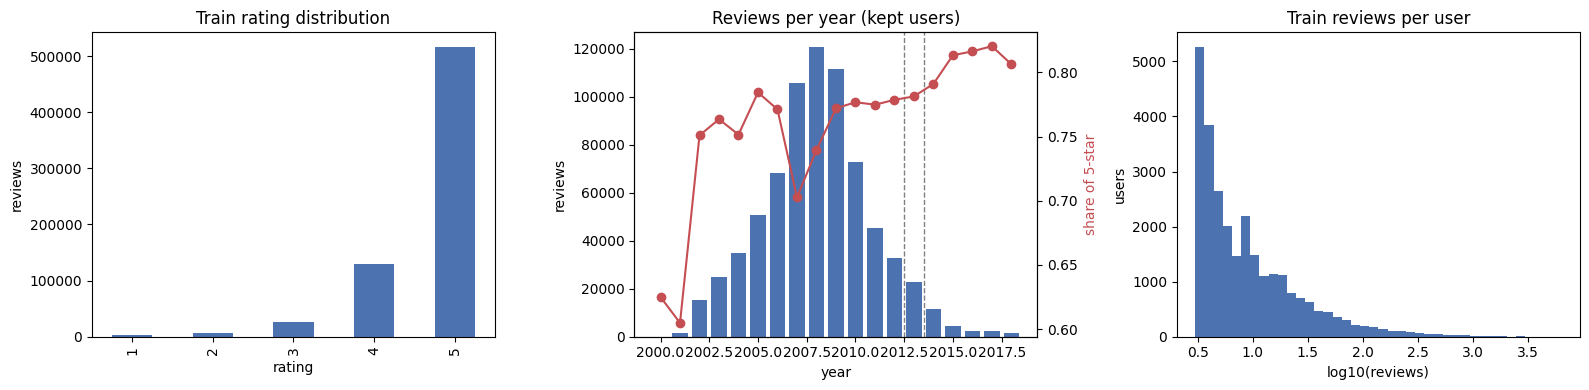

top 1% of users wrote 32.4% of training reviews; median reviews per user 6


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
train.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set(title="Train rating distribution", xlabel="rating", ylabel="reviews")

allr = pd.concat([train, val, test])
by_year = allr.groupby(allr.date.dt.year).agg(reviews=("rating", "size"), p5=("y_eq5", "mean"))
ax[1].bar(by_year.index, by_year.reviews, color="#4C72B0")
ax[1].set(title="Reviews per year (kept users)", xlabel="year", ylabel="reviews")
ax2 = ax[1].twinx(); ax2.plot(by_year.index, by_year.p5, color="#C44E52", marker="o")
ax2.set_ylabel("share of 5-star", color="#C44E52")
for x in (2013, 2014):
    ax[1].axvline(x - 0.5, color="gray", ls="--", lw=1)

hist_len = train.groupby("u").size()
ax[2].hist(np.log10(hist_len), bins=40, color="#4C72B0")
ax[2].set(title="Train reviews per user", xlabel="log10(reviews)", ylabel="users")
plt.tight_layout(); plt.savefig(RESULTS / "eda_overview.png", dpi=150); plt.show()
top1 = hist_len.sort_values(ascending=False).head(len(hist_len) // 100).sum() / len(train)
print(f"top 1% of users wrote {top1:.1%} of training reviews; median reviews per user {hist_len.median():.0f}")

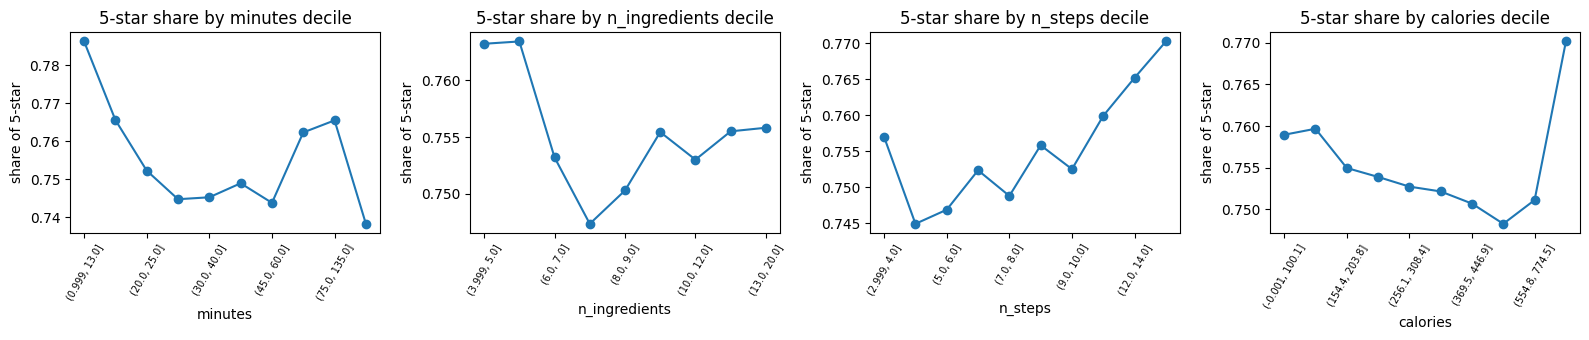

In [5]:
# Does the 5-star share depend on recipe content? (train rows)
tr = train.join(recipes[["minutes", "n_ingredients", "n_steps", "calories"]], on="recipe_id")
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c in zip(ax, ["minutes", "n_ingredients", "n_steps", "calories"]):
    b = pd.qcut(tr[c], 10, duplicates="drop")
    tr.groupby(b, observed=True).y_eq5.mean().plot(ax=a, marker="o")
    a.set(title=f"5-star share by {c} decile", xlabel=c, ylabel="share of 5-star")
    a.tick_params(axis="x", labelrotation=60, labelsize=7)
plt.tight_layout(); plt.savefig(RESULTS / "eda_content.png", dpi=150); plt.show()

In [6]:
# Cold vs warm rows
pd.DataFrame({name: df.groupby("cold").agg(rows=("rating", "size"), p5=("y_eq5", "mean")).stack()
              for name, df in [("validation", val), ("test", test)]})

validation       test
cold                            
0    rows  16523.0000 18125.0000
     p5        0.7835     0.8038
1    rows   6410.0000  4099.0000
     p5        0.7760     0.7960

In [7]:
# Tags carried by most recipes make every pair of recipes look alike
rsets = RecipeSets(recipes)
df_tags = rsets.tag_doc_freq(train.recipe_id.values).sort_values(ascending=False)
print(f"{len(rsets.tag_vocab):,} tags, {len(rsets.ing_vocab):,} ingredients")
for th in MAX_DF_GRID[:-1]:
    print(f"tags in > {th:.0%} of train recipes: {(df_tags > th).sum()}")
df_tags.head(20).to_frame("share of train recipes")

530 tags, 13,627 ingredients
tags in > 20% of train recipes: 18
tags in > 35% of train recipes: 9
tags in > 50% of train recipes: 6
tags in > 75% of train recipes: 4


,share of train recipes
preparation,0.9986
time-to-make,0.9775
course,0.9463
main-ingredient,0.7596
dietary,0.7304
easy,0.5402
occasion,0.4948
cuisine,0.3838
low-in-something,0.3704
equipment,0.3280
